# Домашнее задание 1. Введение в Pytorch и DL. Базовые элементы.

## Пояснение к ячейкам с общим кодом

**Данные.** FashionMNIST: 60 000 обучающих и 10 000 тестовых изображений 28×28 в градациях серого, 10 классов одежды.
* `.float().div(255)` приводит пиксели к диапазону от 0 до 1.
* `.sub(0.2860).div(0.3530)` - стандартизация: из пикселей вычитается среднее, результат делится на стандартное отклонение (оба значения посчитаны по обучающей выборке). После этого вход имеет среднее около 0 и разброс около 1. Числа взяты с https://github.com/sheevec/fashion-mnist-benchmarking
* `.unsqueeze(1)` добавляет ось канала: размер становится `N×1×28×28`.
* Весь датасет хранится на `device`, поэтому `DataLoader` не нужен: батчи берутся срезами.

**`evaluate`.** `@torch.no_grad()` отключает расчёт градиентов: для оценки они не нужны, так экономятся память и время. Функция возвращает loss и accuracy (долю верно угаданных классов) на тестовой выборке.

**`train`** - общий цикл обучения для заданий 1 и 3. От оптимизатора нужны только методы `zero_grad()` и `step()`.
1. Каждую эпоху объекты перемешиваются с фиксированным seed, поэтому у всех запусков порядок батчей одинаковый.
2. За эпоху делается 468 шагов (`60000 // 128`), неполный последний батч отбрасывается.
3. Шаг обучения: прямой проход → loss → `zero_grad()` → `backward()` → `step()`. PyTorch добавляет новые градиенты к старым, поэтому перед `backward()` их обнуляют.
4. Норма градиента - одно число, показывающее общий размер градиентов всех параметров. Считается после `backward()` и до `step()`.
5. Сохраняются веса `Linear`-слоёв до и после обучения и test accuracy после каждой эпохи.

**`smooth`** - скользящее среднее по 50 шагам. Loss на отдельном батче сильно колеблется, сглаживание делает график читаемым.

In [13]:
import math
import unittest

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_data(root="./data"):
    """FashionMNIST целиком в тензорах: x_train, y_train, x_test, y_test."""
    tensors = []
    for train in (True, False):
        ds = datasets.FashionMNIST(root, train=train, download=True)
        x = ds.data.float().div(255).sub(0.2860).div(0.3530).unsqueeze(1)
        tensors += [x.to(device), ds.targets.to(device)]
    return tuple(tensors)


X_TRAIN, Y_TRAIN, X_TEST, Y_TEST = load_data()


@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    logits = model(x)
    loss = F.cross_entropy(logits, y).item()
    accuracy = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, accuracy


def linear_weights(model):
    return [m.weight.detach().cpu().numpy().copy() for m in model.modules() if isinstance(m, nn.Linear)]


def train(model, optimizer, epochs, batch_size=128, seed=0):
    """Обучение. Записывает loss и норму градиента на каждом шаге, test accuracy - по эпохам."""
    generator = torch.Generator().manual_seed(seed)
    history = {
        "loss": [],
        "grad_norm": [],
        "test_acc": [evaluate(model, X_TEST, Y_TEST)[1]],
        "w_init": linear_weights(model),
    }
    batches_per_epoch = len(X_TRAIN) // batch_size
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(X_TRAIN), generator=generator).to(device)
        for i in range(batches_per_epoch):
            idx = perm[i * batch_size:(i + 1) * batch_size]
            loss = F.cross_entropy(model(X_TRAIN[idx]), Y_TRAIN[idx])
            optimizer.zero_grad()
            loss.backward()
            # max_norm=inf: функция только возвращает норму и не меняет градиенты
            grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=float("inf"))
            optimizer.step()
            history["loss"].append(loss.item())
            history["grad_norm"].append(grad_norm.item())
        history["test_acc"].append(evaluate(model, X_TEST, Y_TEST)[1])
    history["w_final"] = linear_weights(model)
    return history


def smooth(values, window=50):
    return np.convolve(values, np.ones(window) / window, mode="valid")

# Задание 1

In [14]:
class BaseNetwork(nn.Module):

    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=(512, 256, 256, 128)):
        """
        Inputs:
            act_fn - Object of the activation function that should be used as non-linearity in the network.
            input_size - Size of the input images in pixels
            num_classes - Number of classes we want to predict
            hidden_sizes - A sequence of integers specifying the hidden layer sizes in the NN
        """
        super().__init__()

        # Create the network based on the specified hidden sizes
        layers = []
        layer_sizes = [input_size] + list(hidden_sizes)
        for layer_index in range(1, len(layer_sizes)):
            layers += [nn.Linear(layer_sizes[layer_index - 1], layer_sizes[layer_index]),
                       act_fn]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)  # ModuleList регистрирует слои, их параметры видны в parameters()

        self.config = {"act_fn": act_fn.__class__.__name__, "input_size": input_size,
                       "num_classes": num_classes, "hidden_sizes": list(hidden_sizes)}

    def forward(self, x):
        x = x.flatten(start_dim=1)
        for layer in self.layers:
            x = layer(x)
        return x

## Пояснение: сеть `BaseNetwork`

Полносвязная сеть (MLP) 784 → 512 → 256 → 256 → 128 → 10 с одной и той же функцией активации после каждого скрытого слоя.
* `nn.ModuleList` регистрирует слои как подмодули, поэтому их параметры доступны через `model.parameters()`.
* Один объект `act_fn` используется после каждого скрытого слоя.
* Последний слой - `Linear` без активации. Он возвращает **логиты** (ненормированные оценки классов). `F.cross_entropy` сам применяет `log_softmax`, поэтому отдельный softmax не нужен.
* `x.flatten(start_dim=1)` превращает тензор `B×1×28×28` в `B×784`.
* `hidden_sizes` по умолчанию задан кортежем, а не списком: изменяемые объекты как значения по умолчанию в Python использовать не рекомендуется.

Активации: ReLU, Tanh, Identity и Sigmoid. 

Инициализации весов: константа 0.1, нормальная с σ=0.01, Xavier, Kaiming. 

Смещения всегда инициализируются нулями.

## Пояснение: активации и инициализации

**Почему инициализация важна.** Каждый слой умножает вход на матрицу весов. Если веса слишком маленькие, значения на выходе слоя получаются меньше, чем на входе, и после нескольких слоёв сигнал почти исчезает. Если веса слишком большие, значения растут от слоя к слою. То же происходит с градиентами при обратном проходе: они либо затухают , либо растут. Хорошая инициализация подбирает размер весов так, чтобы значения и градиенты сохраняли примерно один и тот же масштаб на всех слоях.

**Схемы инициализации**:
* `const 0.1` - все веса равны 0.1. Все нейроны слоя получают одинаковые выходы и одинаковые градиенты, поэтому остаются одинаковыми всё обучение. Слой работает как один нейрон.
* `normal σ=0.01` - случайные, но очень маленькие веса. Сигнал уменьшается от слоя к слою.
* `xavier` - размер весов зависит от числа входов и выходов слоя. Рассчитан на активации, которые около нуля почти линейны (tanh).
* `kaiming` - веса чуть больше, чем у Xavier. Это нужно для ReLU: она обнуляет отрицательные значения, и без увеличения весов сигнал уменьшался бы.
* Смещения всегда равны нулю. Это стандартная практика; симметрию нарушают случайные веса.

**Активации:** `ReLU` - заменяет отрицательные значения нулём; `Tanh` - значения от −1 до 1; `Identity` - ничего не меняет (сеть становится линейной); `Sigmoid` - значения от 0 до 1, её производная всегда небольшая (не больше 0.25).

`make_net(act, init, seed)` задаёт seed, создаёт сеть и применяет выбранную инициализацию ко всем `nn.Linear`, поэтому каждая конфигурация воспроизводима.

In [15]:
ACTS = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "Identity": nn.Identity, "Sigmoid": nn.Sigmoid}
INITS = {
    "const 0.1":     lambda w: nn.init.constant_(w, 0.1),
    "normal σ=0.01": lambda w: nn.init.normal_(w, mean=0.0, std=0.01),
    "xavier":        lambda w: nn.init.xavier_uniform_(w),
    "kaiming":       lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"),
}


def make_net(act, init, seed=42):
    torch.manual_seed(seed)
    net = BaseNetwork(ACTS[act]())
    for m in net.modules():
        if isinstance(m, nn.Linear):
            INITS[init](m.weight)
            nn.init.zeros_(m.bias)
    return net.to(device)

### Активации и градиенты на выходе каждого слоя

Один батч из 512 картинок. «Слой» - это `Linear` + активация. На графиках показаны разброс значений (std) на выходе слоя и типичный размер градиента (RMS) на выходе слоя, в логарифмической шкале.

## Пояснение: как считаются активации и градиенты

`layer_stats` прогоняет батч через сеть вручную и запоминает выход каждого слоя.
* `h.retain_grad()` нужен, потому что PyTorch по умолчанию хранит `.grad` только у параметров. Без этого вызова у выходов слоёв `.grad` был бы пустым.
* `backward()` один раз считает градиенты, после чего у каждого выхода слоя есть `.grad`.
* **std активаций** показывает масштаб значений на выходе слоя.
* **RMS градиента** - корень из среднего квадрата градиента, то есть типичный размер градиента. Он умножается на размер батча, потому что `cross_entropy` усредняет loss по батчу; так результат не зависит от размера батча.
* Ось Y логарифмическая, потому что важны отличия в разы и на порядки.

**Как читать график.** Если линия почти горизонтальна, масштаб сохраняется на всех слоях - это хороший случай. Если линия идёт вниз, значения затухают, если вверх - растут.

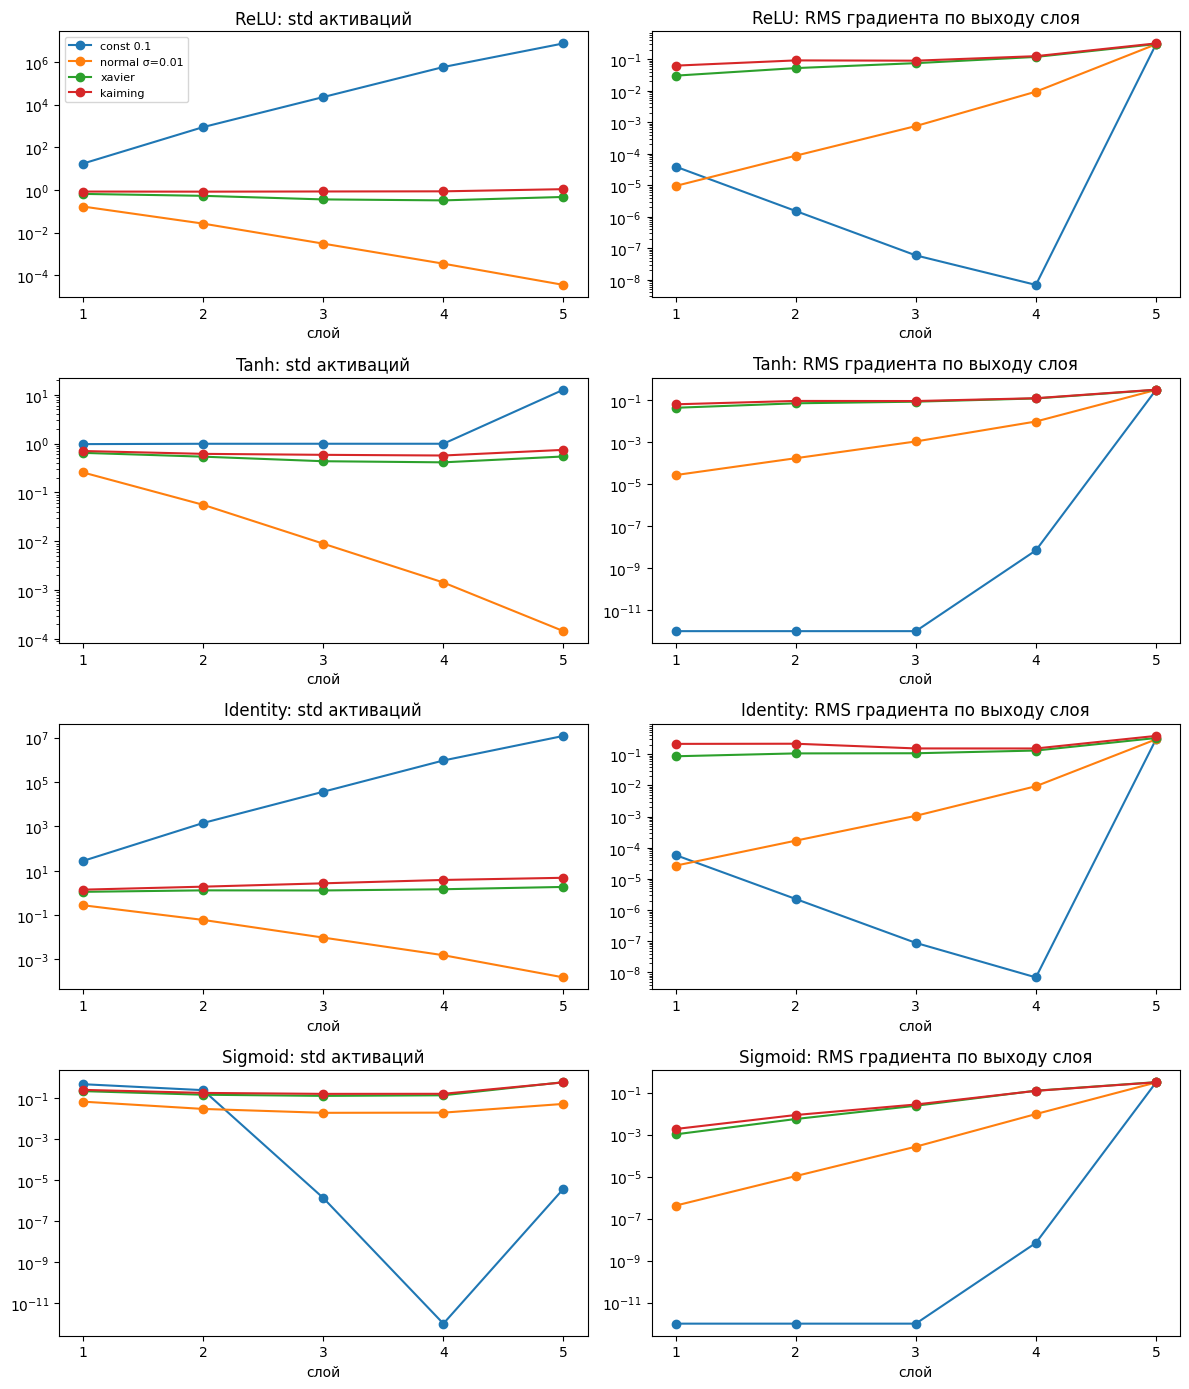

In [16]:
def layer_stats(net, x, y):
    layers = list(net.layers)  # Linear, act, Linear, act, ..., Linear
    h = x.flatten(start_dim=1)
    outputs = []
    for i in range(0, len(layers), 2):
        h = layers[i](h)
        if i + 1 < len(layers):  # у последнего слоя активации нет
            h = layers[i + 1](h)
        h.retain_grad()
        outputs.append(h)
    F.cross_entropy(h, y).backward()
    batch_size = x.size(0)
    act_std = np.array([o.detach().std().item() for o in outputs])
    grad_rms = np.array([(o.grad * batch_size).pow(2).mean().sqrt().item() for o in outputs])
    return act_std, grad_rms


x_batch, y_batch = X_TRAIN[:512], Y_TRAIN[:512]
STATS = {(act, init): layer_stats(make_net(act, init), x_batch, y_batch) for act in ACTS for init in INITS}

fig, axes = plt.subplots(len(ACTS), 2, figsize=(12, 3.5 * len(ACTS)))
for row, act in enumerate(ACTS):
    for col, title in enumerate(["std активаций", "RMS градиента по выходу слоя"]):
        for init in INITS:
            axes[row, col].plot(range(1, 6), np.clip(STATS[(act, init)][col], 1e-12, None), marker="o", label=init)
        axes[row, col].set_yscale("log")
        axes[row, col].set_xticks(range(1, 6))
        axes[row, col].set_title(f"{act}: {title}")
        axes[row, col].set_xlabel("слой")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Какая инициализация стабильна

* **const 0.1** - не подходит ни для одной активации: все нейроны слоя одинаковы.
* **normal σ=0.01** - веса слишком малы, значения и градиенты затухают с глубиной.
* **ReLU** - стабильна при **Kaiming**. Xavier тоже работает, но сигнал немного уменьшается.
* **Tanh** - стабильна при **Xavier**. Kaiming тоже приемлем.
* **Identity** - стабильна при **Xavier**. При Kaiming значения немного растут на каждом слое.
* **Sigmoid** - ни одна схема не даёт стабильных градиентов: её производная мала, поэтому градиенты уменьшаются при движении к входным слоям.

### Сходимость на FashionMNIST (SGD, lr=0.05, batch 128)

## Пояснение: обучение для задания 1

Для каждой пары (активация, инициализация) создаётся сеть и обучается обычным SGD (`torch.optim.SGD`): на каждом шаге веса сдвигаются против градиента, шаг равен `lr` × градиент. Параметры: `lr=0.05`, батч 128, 5 эпох. У всех запусков одинаковые начальные веса и порядок батчей, поэтому разница между кривыми объясняется только парой «активация + инициализация».

Графики:
* **train loss** - среднее значение loss за каждую эпоху;
* **test accuracy** - по эпохам. Точка 0 - качество до обучения.

Если градиенты имеют нормальный масштаб, loss быстро уменьшается. Если градиенты затухают, loss почти не меняется.

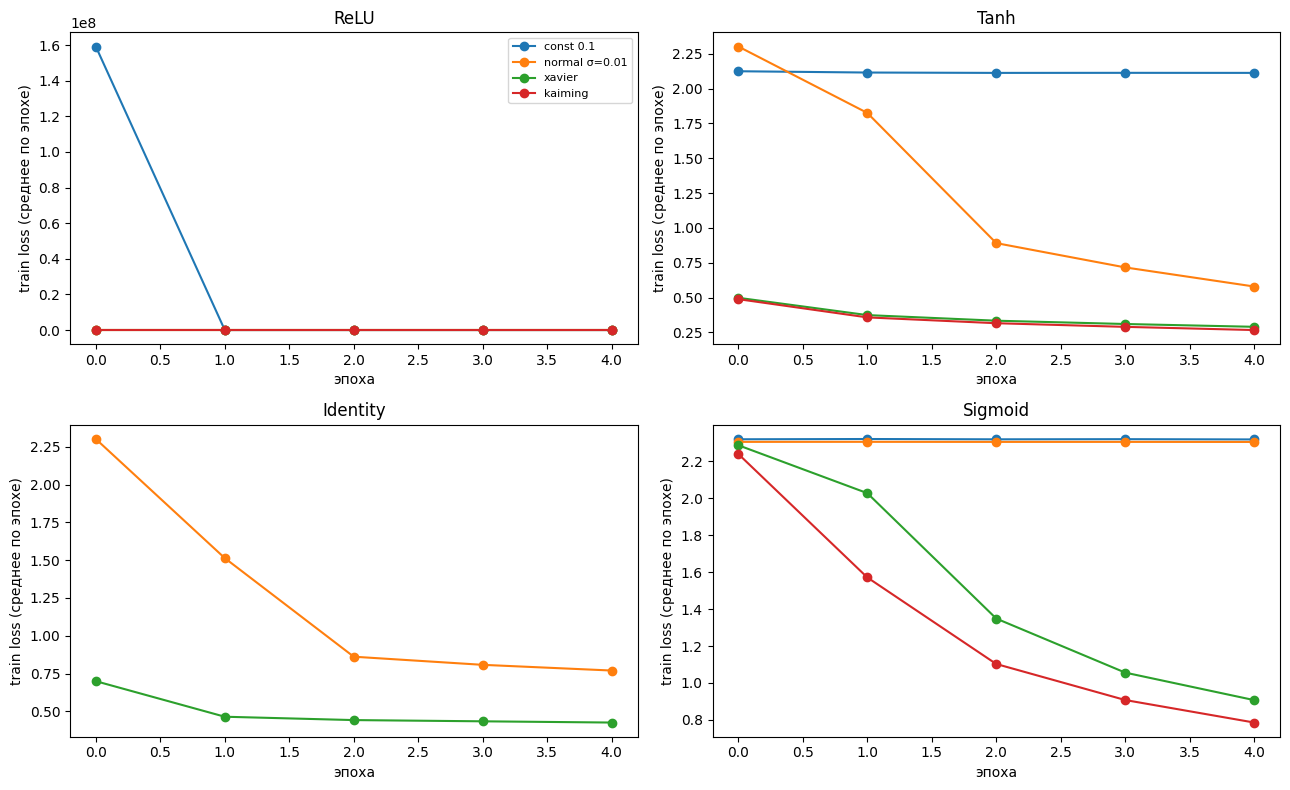

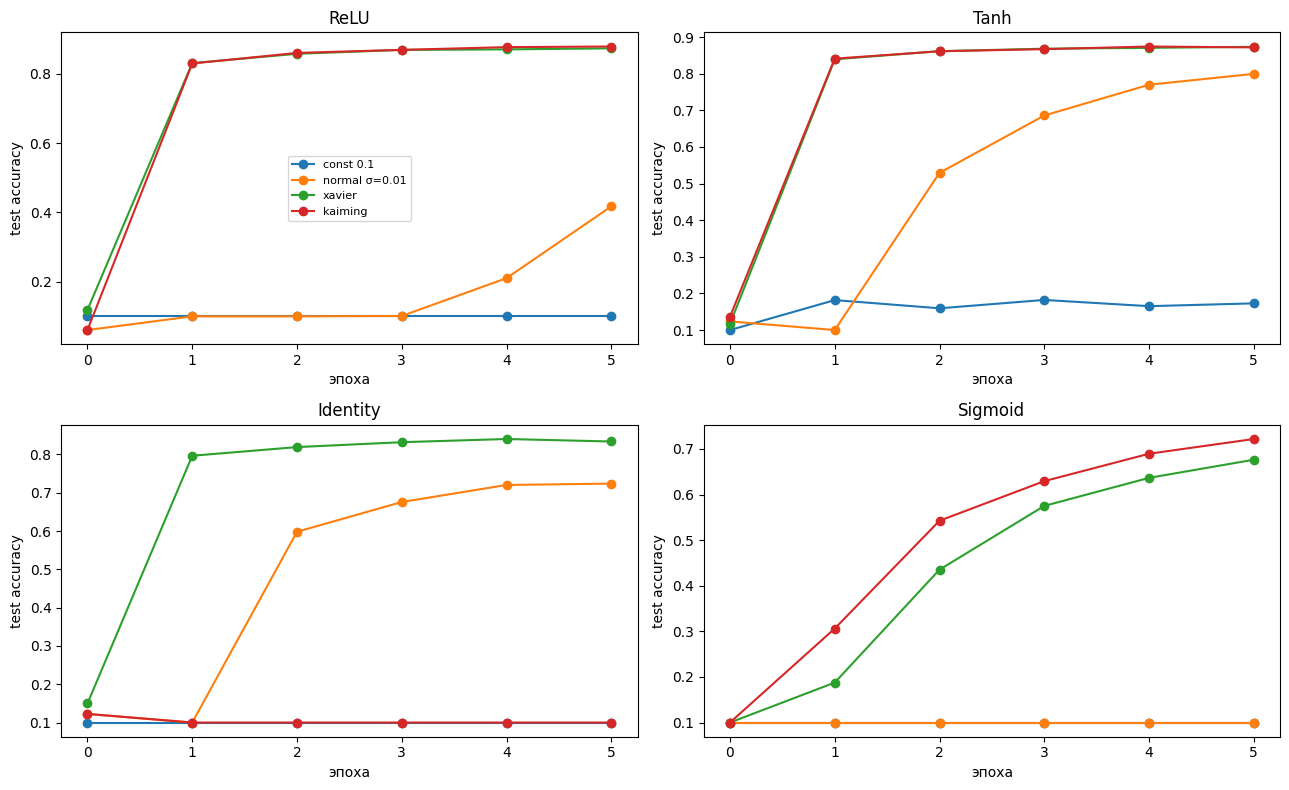

In [17]:
EPOCHS_T1 = 5
RUNS1 = {}
for act in ACTS:
    for init in INITS:
        net = make_net(act, init)
        RUNS1[(act, init)] = train(net, torch.optim.SGD(net.parameters(), lr=0.05), EPOCHS_T1)

for key, ylabel in (("loss", "train loss (среднее по эпохе)"), ("test_acc", "test accuracy")):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, act in zip(axes.ravel(), ACTS):
        for init in INITS:
            values = np.array(RUNS1[(act, init)][key])
            if key == "loss":
                values = values.reshape(EPOCHS_T1, -1).mean(axis=1)
            ax.plot(values, marker="o", label=init)
        ax.set_title(act)
        ax.set_xlabel("эпоха")
        ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

Ожидаемо, лучше всего обучаются пары, стабильные по статистикам выше: ReLU + Kaiming, Tanh + Xavier, Identity + Xavier. Константная инициализация обучается плохо, так как все нейроны слоя одинаковы. При σ=0.01 градиенты затухают, и обучение начинается медленно. Sigmoid сходится медленнее остальных. Точные значения видны на графиках.

---
# Задание 2

In [18]:
class Node:
    """Число, которое запоминает, из каких чисел и какой операцией оно получено."""

    def __init__(self, data, _children=(), _op=""):
        self.data = data                  # значение узла
        self.grad = 0                     # градиент итогового результата по этому узлу
        self._backward = lambda: None     # передача градиента аргументам; у исходных чисел аргументов нет, поэтому ничего не делает
        self._prev = set(_children)       # узлы-аргументы, из которых получен этот узел
        self._op = _op                    # название операции (только для отладки)

    def __repr__(self):
        # как узел выглядит при print
        return f"Node(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        # self + other; если other - обычное число, оборачиваем его в Node
        other = other if isinstance(other, Node) else Node(other)
        # прямой проход: считаем значение и запоминаем аргументы
        out = Node(self.data + other.data, (self, other), "+")

        def _backward():
            # вызывается позже, когда out.grad уже известен.
            # Производная суммы по каждому слагаемому равна 1,
            # поэтому градиент передаётся обоим аргументам без изменений.
            # Используется +=, потому что узел может быть использован несколько раз.
            self.grad += out.grad
            other.grad += out.grad

        out._backward = _backward  # сохраняем функцию в результате, чтобы вызвать её в backward()
        return out

    def __mul__(self, other):
        # self * other
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data * other.data, (self, other), "*")

        def _backward():
            # производная произведения по одному множителю равна значению другого:
            # градиент self = other.data * out.grad, градиент other = self.data * out.grad
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __radd__(self, other):
        # число + Node, например 1 + a: Python вызывает этот метод, потому что у int нет сложения с Node
        return self + other

    def __rmul__(self, other):
        # число * Node, например 4 * a
        return self * other

    def relu(self):
        # ReLU: оставляет положительные значения, остальные заменяет нулём
        out = Node(self.data if self.data > 0 else 0, (self,), "ReLU")

        def _backward():
            # градиент проходит только там, где значение положительное
            # (условие out.data > 0 даёт True или False, то есть 1 или 0)
            self.grad += (out.data > 0) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        # 1. Упорядочиваем узлы так, чтобы каждый узел стоял в списке после всех своих аргументов
        #    (топологическая сортировка). Это нужно, чтобы при обратном проходе
        #    градиент узла был собран от всех мест его использования до того, как он передаётся дальше.
        topo, visited = [], set()

        def build_topo(node):
            if node not in visited:        # каждый узел обрабатываем один раз
                visited.add(node)
                for child in node._prev:   # сначала аргументы
                    build_topo(child)
                topo.append(node)          # потом сам узел

        build_topo(self)

        # 2. Градиент итогового узла по самому себе равен 1
        self.grad = 1  # dL/dL = 1

        # 3. Идём от результата к исходным числам и передаём градиент аргументам
        for node in reversed(topo):
            node._backward()


a = Node(2)
b = Node(-3)
c = Node(10)
d = a + b * c   # d = 2 + (-3) * 10 = -28
e = d.relu()    # e = 0, так как d отрицательное
e.backward()    # считаем градиенты всех узлов
print(a, b, c, d, e)  # у a, b, c, d градиент 0 (ReLU не пропустила его), у e градиент 1

Node(data=2, grad=0) Node(data=-3, grad=0) Node(data=10, grad=0) Node(data=-28, grad=0) Node(data=0, grad=1)


Примечание (возможная ошибка в задании): в примере `d = -28 < 0`, поэтому производная ReLU равна 0 и градиенты `a`, `b`, `c`, `d` равны 0. Значения `b.grad=10`, `c.grad=-3` получились бы только при положительном `d`.

## Пояснение: как устроен autograd в `Node`

**Идея.** Любое вычисление можно представить как граф: узлы - числа, рёбра - операции. Чтобы найти градиент, граф проходят от результата к исходным значениям. В каждом узле градиент результата умножается на локальную производную операции и передаётся аргументам. Если число используется в нескольких местах, вклады складываются.

**Поля узла.**
* `data` - значение;
* `grad` - градиент итогового результата по этому узлу (сначала 0);
* `_prev` - узлы-аргументы;
* `_op` - название операции (для отладки);
* `_backward` - функция, которая передаёт градиент аргументам.

**Операции.**
* Сложение: градиент передаётся обоим аргументам без изменений.
* Умножение: градиент одного аргумента равен значению другого аргумента, умноженному на градиент результата.
* ReLU: градиент передаётся, если значение больше 0, иначе равен 0. В нуле принят 0, как в PyTorch.
* Если вместо `Node` передано обычное число, оно оборачивается в `Node`, поэтому `a * 4 + 1` и `1 + 4 * a` работают.

**Почему градиенты накапливаются (`+=`).** Один узел может использоваться несколько раз, например в `a * a`. Каждое использование даёт свой вклад, и все вклады нужно сложить.

**`backward()`.**
1. Сначала узлы упорядочиваются так, чтобы каждый узел стоял после своих аргументов (топологическая сортировка).
2. Градиент итогового узла полагается равным 1.
3. Список проходится с конца, и у каждого узла вызывается `_backward`. К моменту вызова градиент узла уже собран от всех мест, где он использовался.

**Пример.** `d = 2 + (−3)·10 = −28`, `e = relu(d) = 0`. Для отрицательного значения градиент через ReLU не проходит, поэтому у `a`, `b`, `c`, `d` градиент 0, а у `e` - 1.

## Где здесь автоматическое дифференцирование

Производные не выписываются вручную для каждого выражения: градиенты считаются автоматически в три этапа.

1. **Запись графа.** Каждая операция (`+`, `*`, `relu`) создаёт новый `Node` и запоминает, из каких узлов он получен (`_prev`). Выражение `d = a + b * c` превращается в граф вычислений.
2. **Локальные производные.** У каждой операции есть своя функция `_backward`, которая знает производную только этой операции:
   * сложение передаёт градиент обоим аргументам без изменений;
   * умножение передаёт каждому аргументу значение другого аргумента, умноженное на градиент результата;
   * ReLU передаёт градиент, только если значение положительное.

   Функция создаётся при прямом вычислении, а вызывается позже: градиент результата (`out.grad`) становится известен только после вызова `backward()`.
3. **Обратный проход.** `backward()` упорядочивает узлы так, чтобы каждый стоял после своих аргументов, задаёт градиент итогового узла равным 1 и вызывает `_backward` у узлов в обратном порядке. Градиент шаг за шагом доходит от результата до исходных чисел (правило цепочки). Градиенты накапливаются через `+=`, потому что один узел может использоваться несколько раз.

**Пример.** Для `y = a * b + a` при `a=3`, `b=2` получаем `a.grad = b + 1 = 3` и `b.grad = a = 3`. Эти значения совпадают с ручным расчётом, хотя производные нигде не записывались для выражения целиком.

Используются только обычные числа и арифметика, `torch.autograd` и `torch.nn` не применяются.

## Пояснение: тесты для `Node`

Каждый тест сравнивает результат с ответом, посчитанным вручную.
* `test_add`, `test_mul` - сложение и умножение. Для `a=2`, `b=-3` произведение равно −6, градиент `a` равен −3 (значение `b`), градиент `b` равен 2 (значение `a`).
* `test_relu` - три случая: положительное значение (градиент 1), отрицательное (0), ноль (0).
* `test_example`, `test_positive_branch` - пример из задания (все градиенты 0) и тот же граф с положительным `d`: градиенты `a`, `b`, `c` равны 1, 10, 3.
* `test_node_used_twice` - проверка накопления: для `a*a + a` при `a=3` градиент равен 2·3 + 1 = 7.
* `test_numbers` - операции с обычными числами: для `a*4 + 1` градиент равен 4.
* `test_reversed_operands` - число слева от узла: для `3 + 4*a` градиент равен 4.

In [19]:
class TestNode(unittest.TestCase):
    def test_add(self):
        a, b = Node(2.0), Node(3.0)
        c = a + b
        c.backward()
        self.assertEqual((c.data, a.grad, b.grad), (5.0, 1, 1))

    def test_mul(self):
        a, b = Node(2.0), Node(-3.0)
        c = a * b
        c.backward()
        self.assertEqual((c.data, a.grad, b.grad), (-6.0, -3.0, 2.0))

    def test_relu(self):
        for value, expected_out, expected_grad in ((1.5, 1.5, 1), (-1.5, 0, 0), (0.0, 0.0, 0)):
            a = Node(value)
            r = a.relu()
            r.backward()
            self.assertEqual((r.data, a.grad), (expected_out, expected_grad))

    def test_example(self):
        a, b, c = Node(2), Node(-3), Node(10)
        e = (a + b * c).relu()
        e.backward()
        self.assertEqual([a.grad, b.grad, c.grad, e.grad], [0, 0, 0, 1])

    def test_positive_branch(self):
        a, b, c = Node(2), Node(3), Node(10)
        e = (a + b * c).relu()
        e.backward()
        self.assertEqual([a.grad, b.grad, c.grad], [1, 10, 3])

    def test_node_used_twice(self):
        a = Node(3.0)
        y = a * a + a  # dy/da = 2a + 1
        y.backward()
        self.assertEqual(a.grad, 7.0)

    def test_numbers(self):
        a = Node(2.0)
        y = a * 4 + 1
        y.backward()
        self.assertEqual((y.data, a.grad), (9.0, 4))

    def test_reversed_operands(self):
        a = Node(2.0)
        y = 3 + 4 * a
        y.backward()
        self.assertEqual((y.data, a.grad), (11.0, 4))


unittest.main(argv=[""], exit=False, verbosity=1)

..............
----------------------------------------------------------------------
Ran 14 tests in 0.230s

OK


---
# Задание 3

Реализованы **AdamW** (основной), а также **Momentum**, **Nesterov** и **Adagrad**. Все они обновляют веса по градиенту, но по-разному выбирают размер и направление шага.

* **SGD** (для сравнения) - самый простой вариант. На каждом шаге вес уменьшается на `lr` × текущий градиент. Шаг зависит только от градиента на последнем батче, поэтому траектория получается шумной: градиенты соседних батчей могут заметно отличаться.

* **Momentum** - хранит для каждого веса «скорость». Скорость - это накопленная сумма прошлых градиентов, в которой старые значения постепенно затухают с коэффициентом `μ`. На каждом шаге скорость обновляется: старая скорость умножается на `μ`, и к ней добавляется текущий градиент. Вес меняется на `lr` × скорость, а не на `lr` × градиент.
  * Если градиент много шагов подряд направлен в одну сторону, скорость растёт, и обучение ускоряется. При `μ=0.9` установившийся шаг примерно в 10 раз больше, чем у SGD.
  * Если градиент меняет знак от батча к батчу, положительные и отрицательные значения при накоплении гасят друг друга, и колебания сглаживаются.

* **Nesterov** - вариант Momentum, в котором градиент учитывается точнее. В обычном Momentum шаг делается по скорости, а градиент в ней устаревает: он посчитан в точке, где веса были до сдвига. В методе Нестерова градиент оценивается так, как будто веса уже сдвинулись по скорости. На практике это записывается просто: шаг делается по сумме текущего градиента и скорости, умноженной на `μ`, а не по одной скорости. Скорость обновляется так же, как в Momentum. Благодаря этому метод быстрее реагирует на изменение градиента и меньше «проскакивает» минимум.

* **Adagrad** - подбирает свой размер шага для каждого веса. Для этого он хранит сумму квадратов всех прошлых градиентов этого веса, а шаг делит на корень из этой суммы.
  * Веса, у которых градиенты были большими, получают маленькие шаги. Веса с маленькими или редкими градиентами получают большие шаги. Поэтому не нужно вручную подбирать масштаб шага под каждый вес.
  * Недостаток: сумма квадратов только растёт, значит, шаг только уменьшается. Если обучение долгое, шаг может стать слишком маленьким, и веса почти перестанут меняться.
  * Маленькая константа `ε` в знаменателе защищает от деления на ноль.

* **AdamW** - объединяет идеи Momentum и Adagrad и убирает недостаток Adagrad. Для каждого веса хранятся две величины:
  * **среднее градиента** $m$ (как скорость в Momentum): показывает, в какую сторону в среднем направлен градиент;
  * **среднее квадрата градиента** $v$ (как сумма квадратов в Adagrad): показывает, какого размера обычно градиент.

  Обозначения: $g_t$ - градиент на шаге $t$, $\theta$ - вес, $\eta$ - `lr`, $\lambda$ - `weight_decay`.

  **1. Средние.** Старые значения постепенно забываются (коэффициенты $\beta_1=0.9$ и $\beta_2=0.999$). Поэтому $v$ не растёт без конца, и шаг не уменьшается со временем, как в Adagrad:

  $$m_t=\beta_1 m_{t-1}+(1-\beta_1)\,g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)\,g_t^2.$$

  **2. Поправка на смещение.** Средние $m$ и $v$ начинаются с нуля, поэтому на первых шагах они занижены. Чтобы это исправить, их делят на множители, которые зависят от номера шага $t$ и со временем приближаются к 1:

  $$\hat m_t=\frac{m_t}{1-\beta_1^{\,t}},\qquad \hat v_t=\frac{v_t}{1-\beta_2^{\,t}}.$$

  На первом шаге после поправки $\hat m_1=g_1$ и $\hat v_1=g_1^2$, поэтому шаг по модулю равен $\eta$.

  **3. Обновление веса.** Вес уменьшается на небольшую долю (weight decay), и к нему добавляется шаг по нормированному градиенту:

  $$\theta_t=\theta_{t-1}\,(1-\eta\lambda)\;-\;\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}.$$

  Шаг равен $\hat m_t$, делённому на $\sqrt{\hat v_t}$. Он показывает направление градиента, а его размер почти не зависит от масштаба градиента: если все градиенты умножить на одно число, оно сократится. Поэтому `lr` для AdamW подобрать проще, и его значения обычно меньше (около `1e-3`).

  **Weight decay.** Отличие AdamW от Adam с L2-регуляризацией состоит в том, как уменьшаются веса. В Adam с L2 слагаемое $\lambda\theta$ добавляется к градиенту, а затем делится на $\sqrt{\hat v_t}$, поэтому сила регуляризации зависит от истории градиентов. В AdamW вес умножается на $(1-\eta\lambda)$ независимо от градиента, и регуляризация получается предсказуемой. При $\lambda=0$ AdamW совпадает с Adam.

In [20]:
class Optimizer:
    def __init__(self, params):
        self.params = list(params)
        self.state = {}

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    @torch.no_grad()
    def step(self):
        for i, p in enumerate(self.params):
            if p.grad is not None:
                self._update(p, p.grad, self.state.setdefault(i, {}))


class Momentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        super().__init__(params)
        self.lr, self.mu = lr, momentum

    def _update(self, p, g, state):
        v = state.setdefault("v", torch.zeros_like(p))
        v.mul_(self.mu).add_(g)
        p.add_(v, alpha=-self.lr)


class Nesterov(Momentum):
    def _update(self, p, g, state):
        v = state.setdefault("v", torch.zeros_like(p))
        v.mul_(self.mu).add_(g)
        p.add_(g + self.mu * v, alpha=-self.lr)


class Adagrad(Optimizer):
    def __init__(self, params, lr=0.01, eps=1e-10):
        super().__init__(params)
        self.lr, self.eps = lr, eps

    def _update(self, p, g, state):
        sum_sq = state.setdefault("sum_sq", torch.zeros_like(p))
        sum_sq.addcmul_(g, g)
        p.addcdiv_(g, sum_sq.sqrt().add_(self.eps), value=-self.lr)


class AdamW(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        super().__init__(params)
        self.lr, self.betas, self.eps, self.wd = lr, betas, eps, weight_decay

    def _update(self, p, g, state):
        if not state:
            state.update(t=0, m=torch.zeros_like(p), v=torch.zeros_like(p))
        state["t"] += 1
        beta1, beta2 = self.betas

        p.mul_(1 - self.lr * self.wd)  # weight decay применяется к весам напрямую
        state["m"].mul_(beta1).add_(g, alpha=1 - beta1)
        state["v"].mul_(beta2).addcmul_(g, g, value=1 - beta2)

        bias_corr1 = 1 - beta1 ** state["t"]
        bias_corr2 = 1 - beta2 ** state["t"]
        denom = (state["v"].sqrt() / math.sqrt(bias_corr2)).add_(self.eps)
        p.addcdiv_(state["m"], denom, value=-self.lr / bias_corr1)

## Пояснение: реализация оптимизаторов

**Базовый класс `Optimizer`** повторяет интерфейс `torch.optim`.
* Хранит список параметров и словарь `state` с отдельными данными для каждого параметра (скорость, сумма квадратов и т. д.). Данные создаются при первом использовании.
* `zero_grad()` сбрасывает градиенты.
* `step()` обёрнут в `@torch.no_grad()`: обновление весов не должно попадать в граф вычислений. Параметры без градиента пропускаются.
* Правило обновления одного параметра находится в методе `_update`, который переопределяется в наследниках.

**Momentum.** `v = μ·v + g`, затем `p -= lr·v`. Так устроен SGD с momentum в PyTorch.

**Nesterov.** Скорость обновляется так же, но шаг делается по `g + μ·v`. Класс наследует `Momentum` и меняет только `_update`.

**Adagrad.** `sum_sq += g²`, затем `p -= lr · g / (√sum_sq + ε)`. Маленькое `ε=1e-10` защищает от деления на ноль.

**AdamW.**
1. `p *= (1 − lr·wd)` - weight decay: все веса немного уменьшаются независимо от градиента.
2. Обновляются средние: `m` - среднее градиента, `v` - среднее квадрата градиента.
3. Поправка на смещение: в начале обучения `m` и `v` близки к нулю, поэтому их делят на специальные множители `bias_corr1` и `bias_corr2`.
4. Шаг: `p -= lr · m / (√v + ε)` (с учётом поправок).

При `weight_decay=0` AdamW совпадает с Adam.

### Тесты

## Пояснение: тесты оптимизаторов

Правила проверяются на одном числовом параметре с заданными градиентами, чтобы ответ можно было посчитать вручную. `make_param` создаёт параметр, `apply_step` задаёт градиент и делает один шаг.

* **Momentum** (`lr=0.1`, `μ=0.5`, `g=1`). Шаг 1: скорость 1, параметр 1 − 0.1 = 0.9. Шаг 2: скорость 0.5 + 1 = 1.5, параметр 0.9 − 0.15 = 0.75.
* **Nesterov** (те же числа). Шаг 1: скорость 1, обновление 1 + 0.5·1 = 1.5, параметр 1 − 0.15 = 0.85. Шаг 2: скорость 1.5, обновление 1 + 0.5·1.5 = 1.75, параметр 0.85 − 0.175 = 0.675.
* **Adagrad** (`lr=0.1`, `g=2`). Шаг 1: сумма квадратов 4, шаг 0.1·2/2 = 0.1, параметр 0.9. Шаг 2: сумма квадратов 8, шаг стал меньше.
* **AdamW, первый шаг** (при `ε=0`): отношение среднего градиента к корню из среднего квадрата равно 1, поэтому параметр равен 1·(1 − 0.1·0.5) − 0.1 = 0.85.
* **AdamW, weight decay не зависит от градиента.** При нулевом градиенте вес меняется только за счёт weight decay: 2 → 2·(1 − 0.1·0.1) = 1.98.
* **Сходимость.** Каждый оптимизатор минимизирует расстояние до заданной точки за 600 шагов и должен подойти к ней с точностью 0.01.

In [21]:
def make_param(value=1.0):
    return nn.Parameter(torch.tensor([value], dtype=torch.float64))


def apply_step(optimizer, p, grad):
    p.grad = torch.tensor([grad], dtype=torch.float64)
    optimizer.step()


class TestOptimizers(unittest.TestCase):
    def test_momentum(self):
        p = make_param()
        opt = Momentum([p], lr=0.1, momentum=0.5)
        apply_step(opt, p, 1.0)
        self.assertAlmostEqual(p.item(), 0.9)    # v = 1
        apply_step(opt, p, 1.0)
        self.assertAlmostEqual(p.item(), 0.75)   # v = 1.5

    def test_nesterov(self):
        p = make_param()
        opt = Nesterov([p], lr=0.1, momentum=0.5)
        apply_step(opt, p, 1.0)
        self.assertAlmostEqual(p.item(), 0.85)   # g + mu * v = 1.5
        apply_step(opt, p, 1.0)
        self.assertAlmostEqual(p.item(), 0.675)  # g + mu * v = 1.75

    def test_adagrad(self):
        p = make_param()
        opt = Adagrad([p], lr=0.1)
        apply_step(opt, p, 2.0)
        self.assertAlmostEqual(p.item(), 0.9, places=8)
        apply_step(opt, p, 2.0)
        self.assertAlmostEqual(p.item(), 0.9 - 0.2 / math.sqrt(8), places=8)

    def test_adamw_first_step(self):
        p = make_param()
        opt = AdamW([p], lr=0.1, weight_decay=0.5, eps=0.0)
        apply_step(opt, p, 3.0)  # m_hat / sqrt(v_hat) = 1  =>  p = p * (1 - lr * wd) - lr
        self.assertAlmostEqual(p.item(), (1 - 0.1 * 0.5) - 0.1, places=10)

    def test_adamw_decay_is_decoupled(self):
        p = make_param(2.0)
        opt = AdamW([p], lr=0.1, weight_decay=0.1)
        apply_step(opt, p, 0.0)
        self.assertAlmostEqual(p.item(), 2.0 * (1 - 0.1 * 0.1), places=12)

    def test_convergence(self):
        target = torch.tensor([3.0, -2.0, 0.5], dtype=torch.float64)
        makers = {
            "Momentum": lambda params: Momentum(params, lr=0.05, momentum=0.9),
            "Nesterov": lambda params: Nesterov(params, lr=0.05, momentum=0.9),
            "Adagrad":  lambda params: Adagrad(params, lr=0.5),
            "AdamW":    lambda params: AdamW(params, lr=0.1, weight_decay=1e-3),
        }
        for name, make_opt in makers.items():
            with self.subTest(name):
                x = nn.Parameter(torch.zeros(3, dtype=torch.float64))
                opt = make_opt([x])
                for _ in range(600):
                    opt.zero_grad()
                    ((x - target) ** 2).sum().backward()
                    opt.step()
                self.assertTrue(torch.allclose(x.detach(), target, atol=1e-2))


unittest.main(argv=[""], exit=False, verbosity=1)

..............
----------------------------------------------------------------------
Ran 14 tests in 0.205s

OK


### Модель из классной работы

## Пояснение: `MyFlatten` и модель

`MyFlatten` превращает тензор `B×C×H×W` в `B×(C·H·W)`. Для входа `2×3×16×16` получится `2×768`, потому что 3·16·16 = 768. Используется `reshape`: в отличие от `view`, он работает и с тензорами, которые хранятся в памяти не подряд.

`NeuralNetwork` - полносвязная сеть 784 → 512 → 512 → 10 с ReLU. `make_model(seed)` задаёт seed до создания модели, поэтому у всех оптимизаторов одинаковые начальные веса. Используется стандартная инициализация PyTorch для `nn.Linear`.

In [22]:
class MyFlatten(nn.Module):
    def forward(self, x):
        return x.reshape(x.size(0), -1)


print(MyFlatten()(torch.randn(2, 3, 16, 16)).shape)  # torch.Size([2, 768])


class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = MyFlatten()
        self.fc = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.fc(x)
        return logits


def make_model(seed=42):
    torch.manual_seed(seed)
    return NeuralNetwork().to(device)


print(make_model())

torch.Size([2, 768])
NeuralNetwork(
  (flatten): MyFlatten()
  (fc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


### Сходимость на FashionMNIST

## Пояснение: эксперимент для задания 3

По условию сходимость нужно показать на модели из классной работы и на модели из задания 1, поэтому эксперимент выполняется для двух моделей:
* **модель из классной работы** - `NeuralNetwork` (784 → 512 → 512 → 10, ReLU, стандартная инициализация PyTorch);
* **`BaseNetwork` из задания 1** - 784 → 512 → 256 → 256 → 128 → 10. Взята пара «ReLU + Kaiming», которая в задании 1 оказалась стабильной по активациям и градиентам.

Четыре оптимизатора обучают каждую модель с одинаковыми начальными весами и порядком батчей (5 эпох, батч 128). Гиперпараметры: Momentum и Nesterov - `lr=0.01, μ=0.9`; Adagrad - `lr=0.01`; AdamW - `lr=1e-3, weight_decay=0.01`. Гиперпараметры не подбирались, поэтому сравнение методов носит иллюстративный характер.

Для каждой модели строятся три графика:
* **train loss** - скользящее среднее, логарифмическая шкала;
* **норма градиента** - скользящее среднее, логарифмическая шкала; обычно уменьшается вместе с loss;
* **test accuracy** - по эпохам.

Модель из классной работы | Momentum: test acc = 0.8755
Модель из классной работы | Nesterov: test acc = 0.8778
Модель из классной работы | Adagrad: test acc = 0.8851
Модель из классной работы | AdamW: test acc = 0.8763
BaseNetwork из задания 1 (ReLU + Kaiming) | Momentum: test acc = 0.8811
BaseNetwork из задания 1 (ReLU + Kaiming) | Nesterov: test acc = 0.8815
BaseNetwork из задания 1 (ReLU + Kaiming) | Adagrad: test acc = 0.8846
BaseNetwork из задания 1 (ReLU + Kaiming) | AdamW: test acc = 0.8808


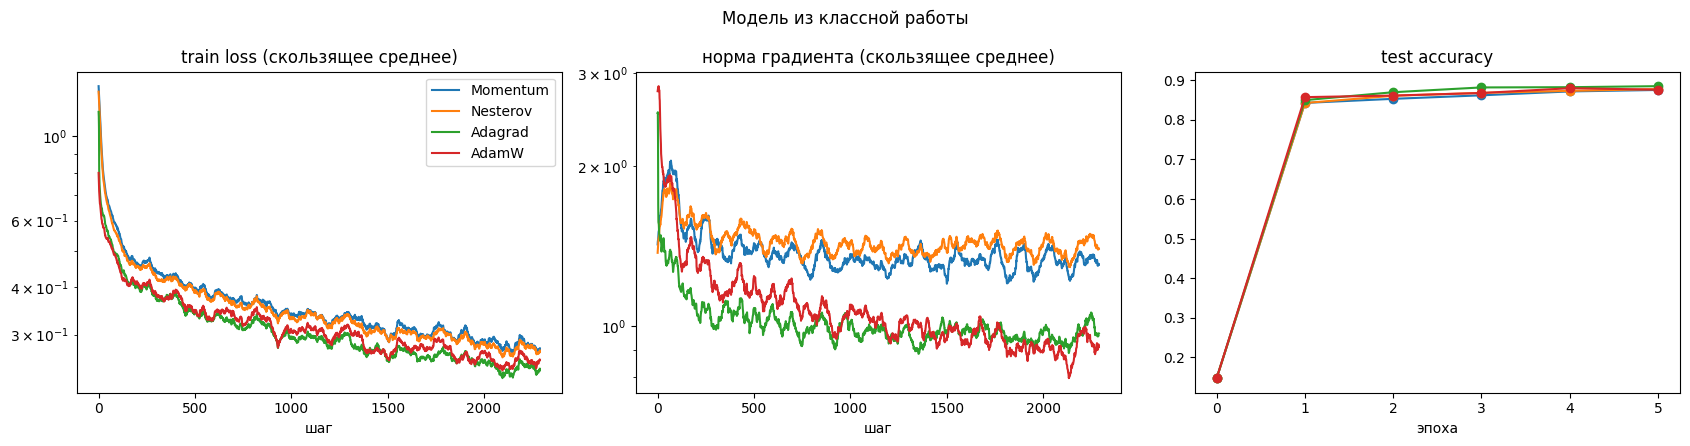

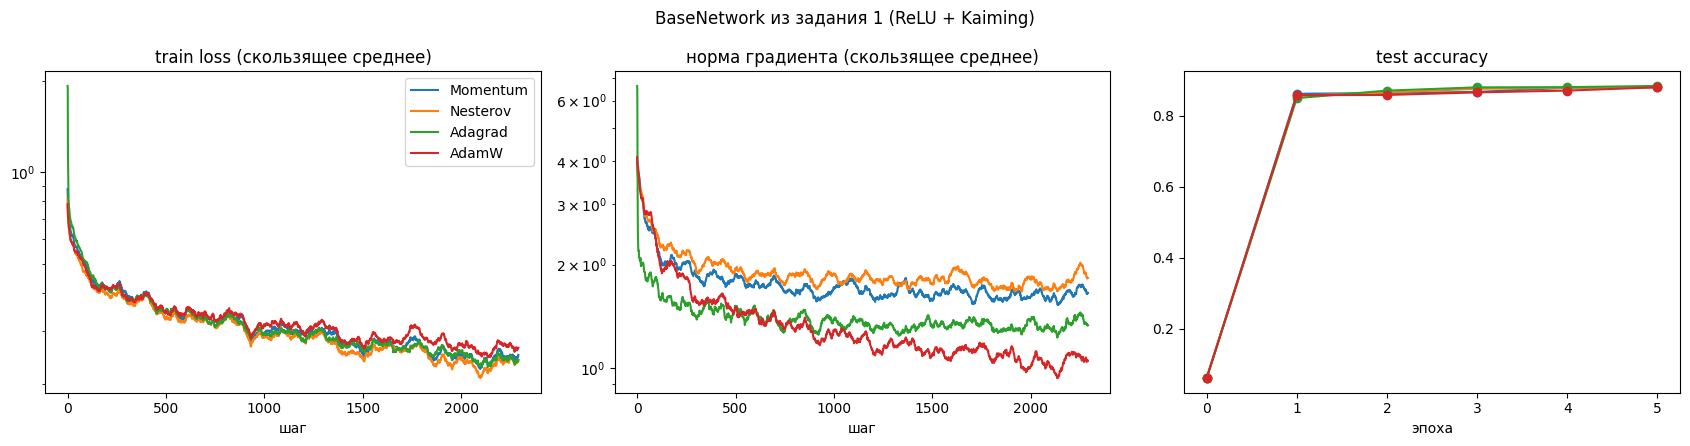

In [23]:
EPOCHS_T3 = 5
OPTS = {
    "Momentum": lambda params: Momentum(params, lr=0.01, momentum=0.9),
    "Nesterov": lambda params: Nesterov(params, lr=0.01, momentum=0.9),
    "Adagrad":  lambda params: Adagrad(params, lr=0.01),
    "AdamW":    lambda params: AdamW(params, lr=1e-3, weight_decay=0.01),
}
MODELS = {
    "Модель из классной работы": make_model,
    "BaseNetwork из задания 1 (ReLU + Kaiming)": lambda: make_net("ReLU", "kaiming"),
}

RUNS3 = {}  # RUNS3[модель][оптимизатор] = история обучения
for model_name, make in MODELS.items():
    RUNS3[model_name] = {}
    for opt_name, make_opt in OPTS.items():
        model = make()
        RUNS3[model_name][opt_name] = train(model, make_opt(model.parameters()), EPOCHS_T3)
        acc = RUNS3[model_name][opt_name]["test_acc"][-1]
        print(f"{model_name} | {opt_name}: test acc = {acc:.4f}")

for model_name, runs in RUNS3.items():
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    fig.suptitle(model_name)
    for opt_name, history in runs.items():
        axes[0].plot(smooth(history["loss"]), label=opt_name)
        axes[1].plot(smooth(history["grad_norm"]), label=opt_name)
        axes[2].plot(history["test_acc"], marker="o", label=opt_name)
    axes[0].set_title("train loss (скользящее среднее)")
    axes[0].set_yscale("log")
    axes[1].set_title("норма градиента (скользящее среднее)")
    axes[1].set_yscale("log")
    axes[2].set_title("test accuracy")
    axes[0].set_xlabel("шаг")
    axes[1].set_xlabel("шаг")
    axes[2].set_xlabel("эпоха")
    axes[0].legend()
    plt.tight_layout()
    plt.show()

### Распределения весов (до и после обучения)

## Пояснение: распределения весов

Для каждой модели, каждого оптимизатора и каждого `Linear`-слоя строятся гистограммы весов до обучения (серая) и после (цветная). У модели из классной работы 3 слоя, у `BaseNetwork` - 5. `density=True` приводит гистограммы к одному масштабу, а `np.percentile(..., [0.1, 99.9])` отсекает редкие выбросы, чтобы ось была читаемой.

Чем сильнее различаются гистограммы, тем больше изменились веса. Если они почти совпадают, веса менялись мало. У AdamW дополнительно действует weight decay.

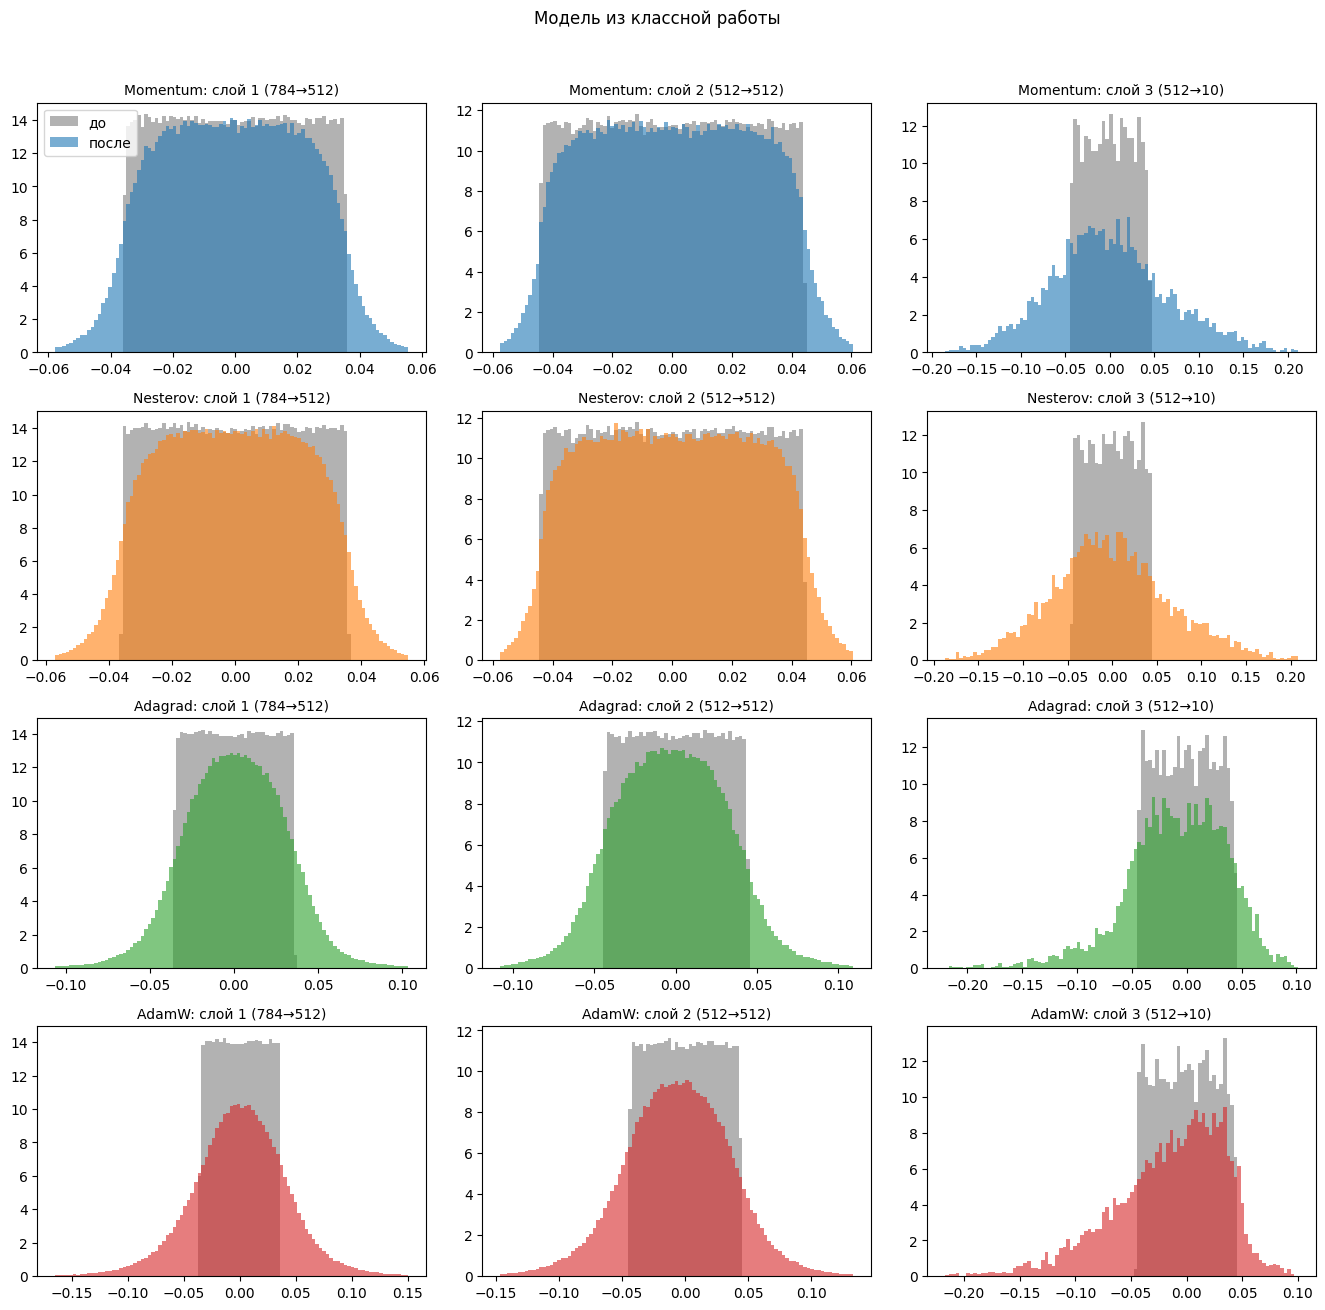

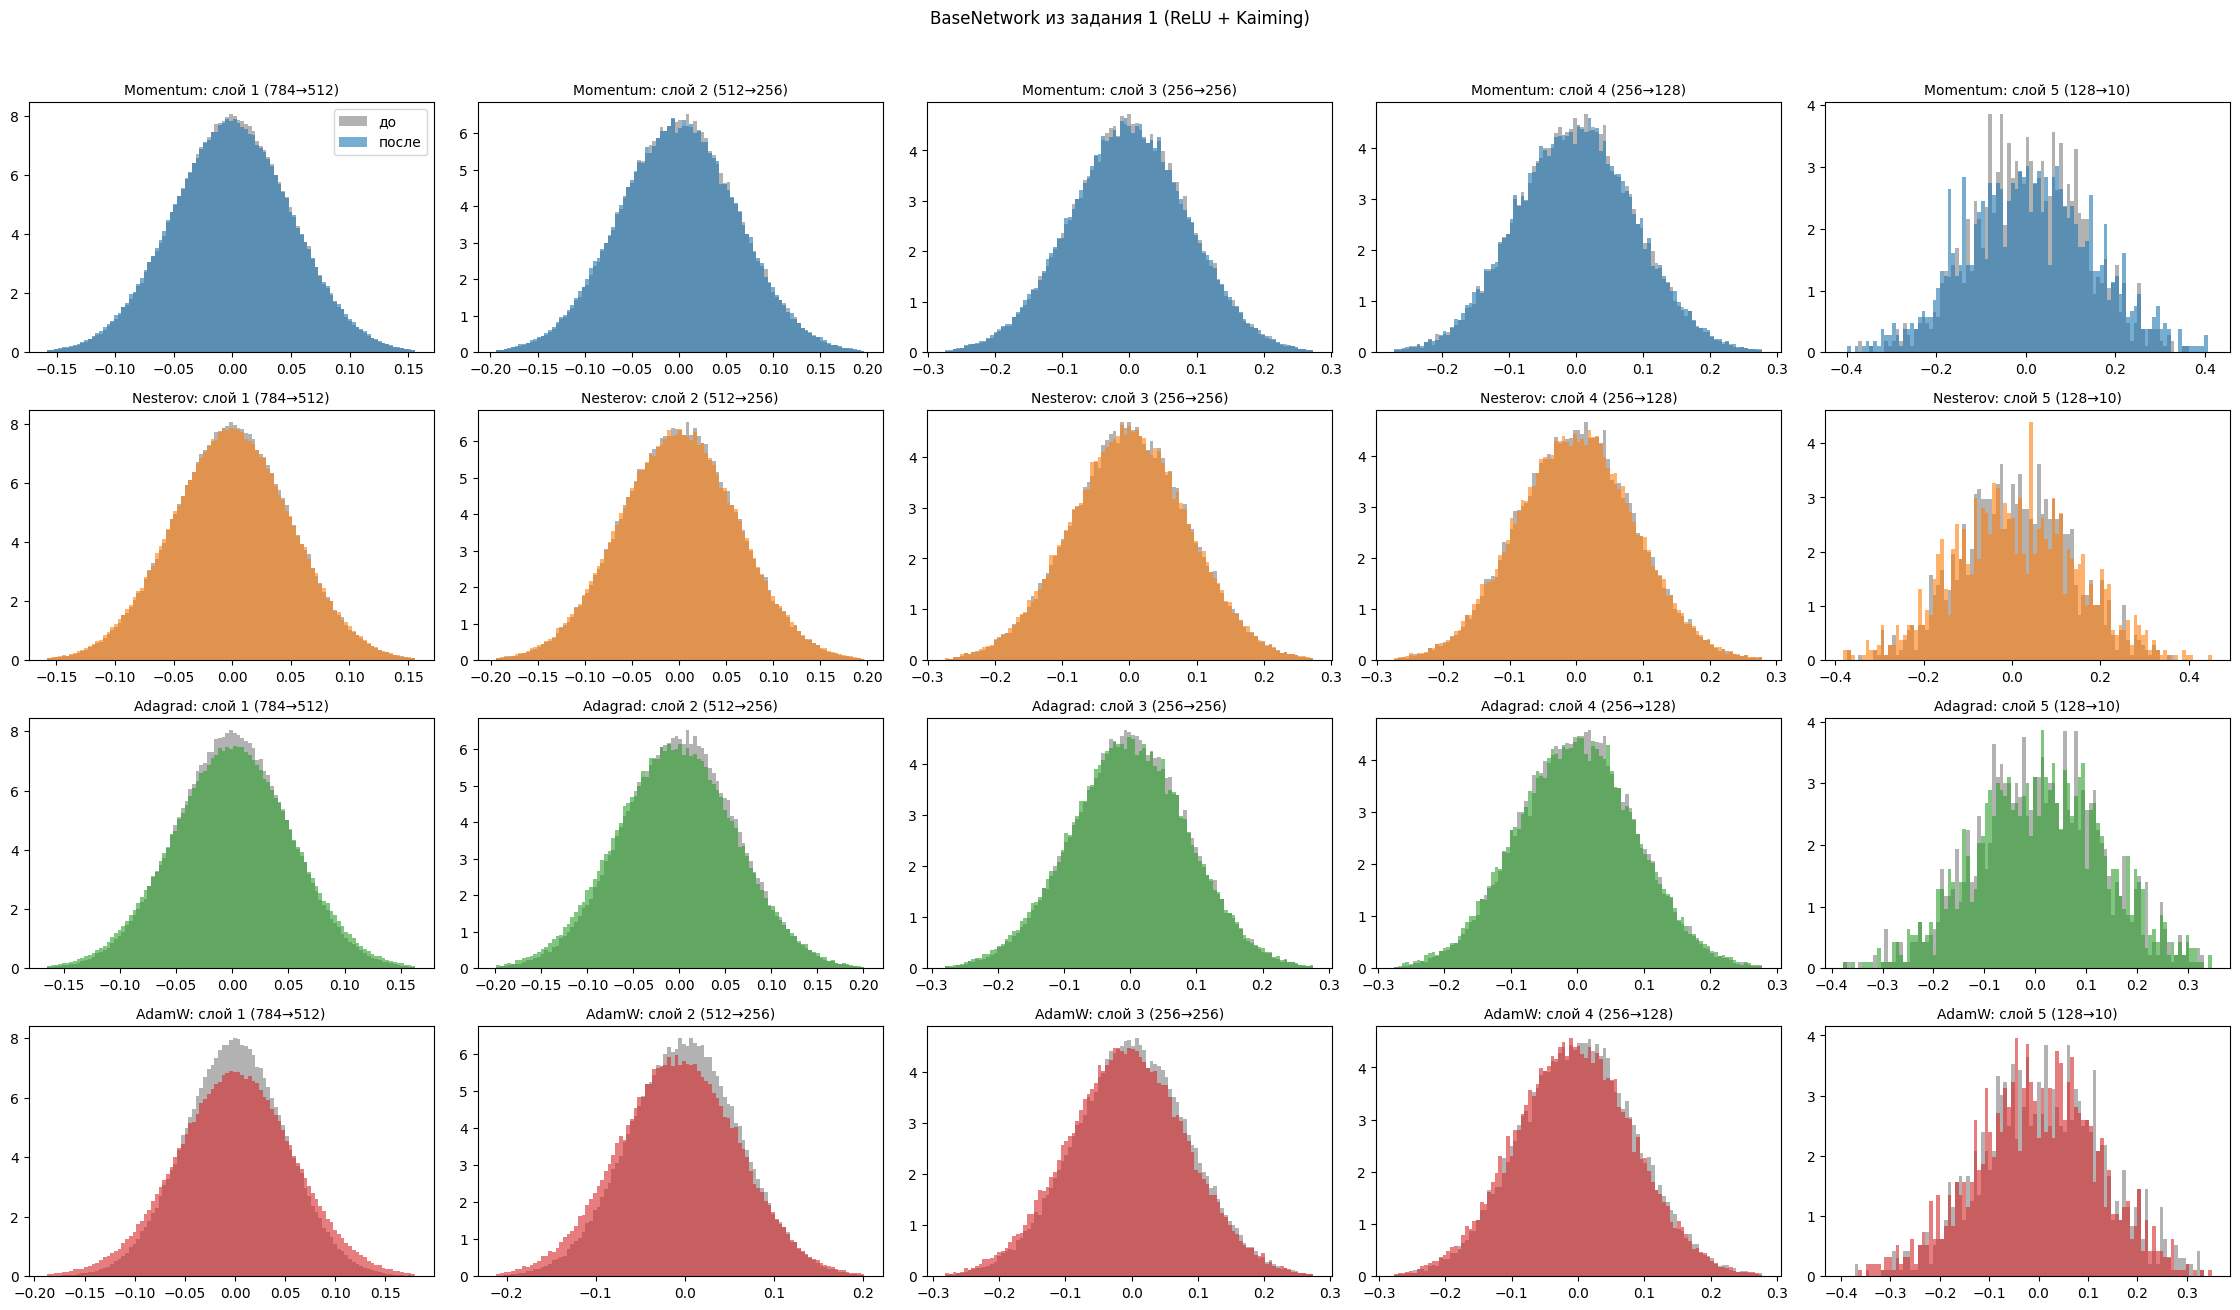

In [24]:
for model_name, runs in RUNS3.items():
    n_layers = len(next(iter(runs.values()))["w_init"])
    fig, axes = plt.subplots(len(runs), n_layers, figsize=(4.5 * n_layers, 3.2 * len(runs)), squeeze=False)
    fig.suptitle(model_name, y=1.02)
    for row, (opt_name, history) in enumerate(runs.items()):
        for layer in range(n_layers):
            out_dim, in_dim = history["w_init"][layer].shape
            w_before = history["w_init"][layer].ravel()
            w_after = history["w_final"][layer].ravel()
            low, high = np.percentile(np.concatenate([w_before, w_after]), [0.1, 99.9])
            bins = np.linspace(low, high, 100)
            axes[row, layer].hist(w_before, bins=bins, color="gray", alpha=0.6, density=True, label="до")
            axes[row, layer].hist(w_after, bins=bins, color=f"C{row}", alpha=0.6, density=True, label="после")
            axes[row, layer].set_title(f"{opt_name}: слой {layer + 1} ({in_dim}→{out_dim})", fontsize=10)
    axes[0, 0].legend()
    plt.tight_layout()
    plt.show()